# Divvy Bike Q3 2019 - Spark ML & GraphFrames | Group 6


---

## What this notebook does

We analyze **Divvy Q3 2019 trip data** (July to September, Chicago's summer peak) using Apache Spark to answer two business questions:

| # | Business Problem | Technique |
|---|---|---|
| 1 | **Network Imbalance:** which stations gain or lose bikes during peak season, and how should Divvy route its rebalancing vans? | GraphFrames: PageRank, Degree, Net Flow, Triangle Count |
| 2 | **Customer Conversion:** can we predict whether a rider is a Subscriber or casual Customer based on ride behavior, and target likely converters with discounts? | Spark ML: Random Forest Classifier (compared against Logistic Regression and Decision Tree) |

---

## Dataset

| Property | Value |
|---|---|
| **Source** | Divvy Bike-Sharing, Chicago, Q3 2019 (July, August, September) |
| **File** | `Divvy_Trips_2019_Q3.csv` |
| **HDFS Path** | `http://localhost:50070/explorer.html#/datalake/raw/divvy` |
| **HDFS Explorer** | [localhost:50070](http://localhost:50070/explorer.html#/datalake/raw) |

> **AI Disclaimer:** We used Claude as support tools during this project. Specifically, AI helped us with: implementing `TrainValidationSplit` with `ParamGridBuilder` (which was mentioned in the Apache Spark ML API lab but not coded there), writing the matplotlib ROC and F1 curve plotting code, debugging `OneHotEncoder` `handleInvalid` errors, and polishing some of the markdown explanations. The pipeline design, feature selection decisions, all graph interpretations, and business conclusions are our own work. Where we extend beyond what the labs taught, we note it in the comments.

## Table of Contents

1. [Environment Setup](#1-environment-setup)
2. [Create Spark Session](#2-create-spark-session)
3. [Load & Inspect Data](#3-load--inspect-data)
4. [Cleaning & Feature Engineering](#4-cleaning--feature-engineering)
5. [Exploratory Data Analysis (EDA)](#5-exploratory-data-analysis-eda)
6. [Spark ML: Customer Conversion Classifier](#6-spark-ml-customer-conversion-classifier)
7. [GraphFrames: Station Network and Imbalance](#7-graphframes-station-network-and-imbalance)
8. [Visualizations and Business Insights](#8-visualizations-and-business-insights)
9. [Summary of Findings](#summary-of-findings)

## Pipeline Architecture

Quick overview of how data flows through our notebook:



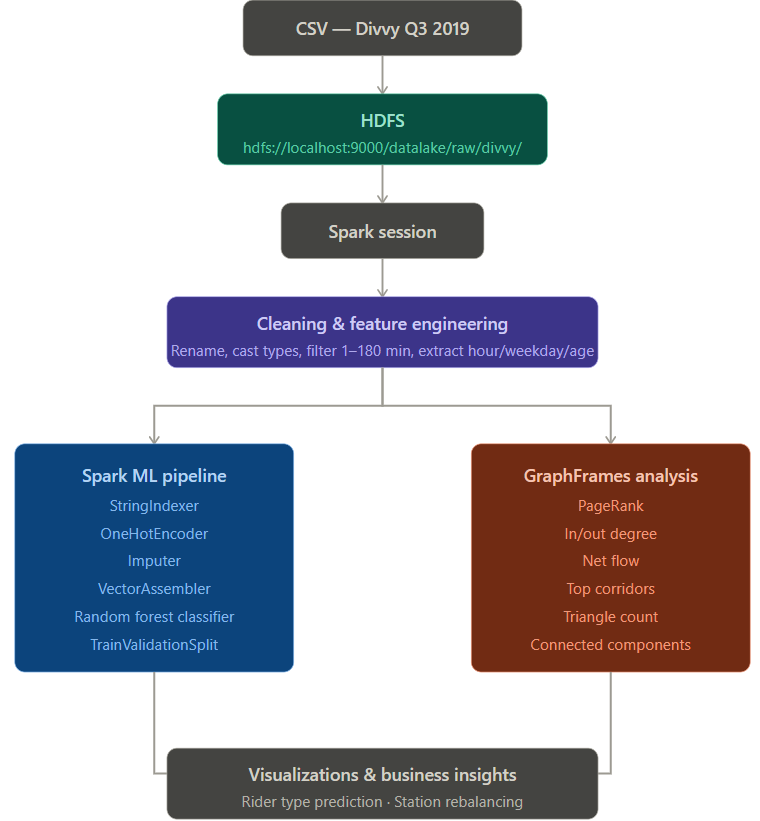

## 1) Environment Setup

In [1]:
import os
os.environ['PYSPARK_SUBMIT_ARGS'] = '--packages graphframes:graphframes:0.8.3-spark3.5-s_2.12 pyspark-shell'

We'll rely on **Pandas** for displaying results, same setup as the class labs:

In [2]:
import pandas as pd
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 20)

## 2) Create Spark Session

The `SparkSession` is the entry point to Spark's DataFrame API. We create one session and Spark reuses it if it already exists (`.getOrCreate()`), same as we did in every lab:

In [3]:
from pyspark.sql.session import SparkSession

spark_session = SparkSession.builder \
    .appName("Divvy Bike Chicago Analysis") \
    .getOrCreate()

print(f"This cluster relies on Spark '{spark_session.version}'")

26/03/17 23:36:26 WARN Utils: Your hostname, osbdet resolves to a loopback address: 127.0.0.1; using 10.0.2.15 instead (on interface enp0s3)
26/03/17 23:36:26 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/home/osbdet/.jupyter_venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/osbdet/.ivy2/cache
The jars for the packages stored in: /home/osbdet/.ivy2/jars
graphframes#graphframes added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-d44bff4b-8079-40c6-b186-52046283e433;1.0
	confs: [default]
	found graphframes#graphframes;0.8.3-spark3.5-s_2.12 in spark-packages
	found org.slf4j#slf4j-api;1.7.16 in central
:: resolution report :: resolve 319ms :: artifacts dl 10ms
	:: modules in use:
	graphframes#graphframes;0.8.3-spark3.5-s_2.12 from spark-packages in [default]
	org.slf4j#slf4j-api;1.7.16 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   2   |   0   |   0   |   0   ||   2   |   0   |
	--------------------------------

This cluster relies on Spark '3.5.4'


> Data is loaded directly from HDFS throughout this notebook (`hdfs://localhost:9000/datalake/raw/divvy/`). No object storage configuration is required.

## 3) Load & Inspect Data

We load the Divvy Q3 2019 CSV from HDFS into a Spark DataFrame. `inferSchema` lets Spark detect column types automatically, and `header=true` uses the first row as column names. Same pattern as the Apache Spark ML API lab:

In [4]:
# the Chicago Divvy Q3 2019 Data file has a few duplicate rows so we remove them at load time
divvy_df = spark_session.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("hdfs://localhost:9000/datalake/raw/divvy/") \
    .distinct()

26/03/17 23:36:49 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors
                                                                                

Let's check the data loaded correctly -- row count, schema, and a quick preview:

In [5]:
print("Rows:", divvy_df.count(), "| Columns:", len(divvy_df.columns))
divvy_df.printSchema()
divvy_df.limit(5).toPandas()

Rows: 1640718 | Columns: 12
root
 |-- trip_id: integer (nullable = true)
 |-- start_time: timestamp (nullable = true)
 |-- end_time: timestamp (nullable = true)
 |-- bikeid: integer (nullable = true)
 |-- tripduration: string (nullable = true)
 |-- from_station_id: integer (nullable = true)
 |-- from_station_name: string (nullable = true)
 |-- to_station_id: integer (nullable = true)
 |-- to_station_name: string (nullable = true)
 |-- usertype: string (nullable = true)
 |-- gender: string (nullable = true)
 |-- birthyear: integer (nullable = true)



,trip_id,start_time,end_time,bikeid,tripduration,from_station_id,from_station_name,to_station_id,to_station_name,usertype,gender,birthyear
0,23479618,2019-07-01 04:59:40,2019-07-01 05:09:11,1183,571.0,38,Clark St & Lake St,71,Morgan St & Lake St,Subscriber,Male,1988
1,23479636,2019-07-01 05:09:48,2019-07-01 05:21:20,1664,692.0,94,Clark St & Armitage Ave,300,Broadway & Barry Ave,Subscriber,Female,1970
2,23480327,2019-07-01 06:48:54,2019-07-01 12:46:35,4683,"21,461.0",319,Greenview Ave & Diversey Pkwy,13,Wilton Ave & Diversey Pkwy,Customer,Male,1995
3,23480343,2019-07-01 06:49:37,2019-07-01 07:03:01,1673,804.0,175,Wells St & Polk St,52,Michigan Ave & Lake St,Subscriber,Female,1974
4,23480639,2019-07-01 07:07:11,2019-07-01 07:17:10,1799,599.0,638,Clinton St & Jackson Blvd,43,Michigan Ave & Washington St,Subscriber,Male,1990


## 4) Cleaning & Feature Engineering

The CSV columns use Divvy's original naming convention. We rename them to snake_case to keep things consistent, then build the features we'll need for both the ML classifier and the graph analysis:

In [6]:
from pyspark.sql import functions as F

rename_map = {
    "tripduration"     : "trip_duration",
    "from_station_id"  : "start_station_id",
    "from_station_name": "start_station_name",
    "to_station_id"    : "end_station_id",
    "to_station_name"  : "end_station_name",
    "birthyear"        : "birth_year",
    "usertype"         : "user_type",
}

divvy_renamed_df = divvy_df
for old, new in rename_map.items():
    if old in divvy_renamed_df.columns:
        divvy_renamed_df = divvy_renamed_df.withColumnRenamed(old, new)

divvy_renamed_df.printSchema()

root
 |-- trip_id: integer (nullable = true)
 |-- start_time: timestamp (nullable = true)
 |-- end_time: timestamp (nullable = true)
 |-- bikeid: integer (nullable = true)
 |-- trip_duration: string (nullable = true)
 |-- start_station_id: integer (nullable = true)
 |-- start_station_name: string (nullable = true)
 |-- end_station_id: integer (nullable = true)
 |-- end_station_name: string (nullable = true)
 |-- user_type: string (nullable = true)
 |-- gender: string (nullable = true)
 |-- birth_year: integer (nullable = true)



`start_time` and `end_time` were correctly parsed as `timestamp` by Spark's schema inference, so no manual conversion needed. `trip_duration` has comma-formatted numbers (e.g. `21,461.0`) so we strip the commas before casting to double, then convert seconds to minutes:

In [7]:
# Divvy exports duration with commas (e.g. "21,461.0") so we strip them first
# If duration is still missing, we compute it from start/end timestamps as a fallback
divvy_cleaned_df = divvy_renamed_df.withColumn(
    "duration_min",
    F.when(
        F.col("trip_duration").isNotNull(),
        F.regexp_replace(F.col("trip_duration"), ",", "").cast("double") / 60.0
    )
    .when(
        F.col("start_time").isNotNull() & F.col("end_time").isNotNull(),
        (F.col("end_time").cast("long") - F.col("start_time").cast("long")) / 60.0
    )
    .otherwise(F.lit(None).cast("double"))
)

Since Spark already parsed `start_time` as a timestamp, we can extract the time features we need directly. We'll use these in the EDA and as inputs for the classifier:

In [8]:
divvy_cleaned_df = (
    divvy_cleaned_df
    .withColumn("start_hour", F.hour("start_time"))
    .withColumn("start_wday", F.date_format("start_time", "E"))
    .withColumn("start_date", F.to_date("start_time"))
    .withColumn("month",      F.month("start_time"))
    .withColumn("year",       F.year("start_time"))
)

We calculate rider age from `birth_year`. This could be a useful predictor since younger and older riders probably have different subscription patterns:

In [9]:
divvy_cleaned_df = divvy_cleaned_df.withColumn(
    "rider_age",
    F.when(
        F.col("birth_year").isNotNull() & F.col("year").isNotNull(),
        (F.col("year") - F.col("birth_year")).cast("double")
    ).otherwise(F.lit(None).cast("double"))
)

Gender is already stored as a string ("Male", "Female", or blank). We just standardize the column name to `gender_label` and fill blanks with "Unknown" so there are no nulls going into the model:

In [10]:
divvy_cleaned_df = divvy_cleaned_df.withColumn(
    "gender_label",
    F.when(F.col("gender") == "Male",   F.lit("Male"))
     .when(F.col("gender") == "Female", F.lit("Female"))
     .otherwise(F.lit("Unknown"))
)

We decided to keep only trips between 1 and 180 minutes. Anything under a minute is almost certainly a failed undock, and anything over 3 hours is probably a lost or unreturned bike. We also `.cache()` here since the DataFrame is ~1.6M rows and we'll be hitting it multiple times across EDA, ML and GraphFrames, and without this Spark would re-read from HDFS every single time:

In [11]:
divvy_final_df = (
    divvy_cleaned_df
    .filter((F.col("duration_min") >= 1.0) & (F.col("duration_min") <= 180.0))
    .cache()
)

print("Total rows after cleaning:", divvy_final_df.count())

divvy_final_df.select(
    "duration_min", "start_hour", "start_wday", "rider_age", "user_type", "gender_label"
).limit(5).toPandas()

Total rows after cleaning: 1633444


,duration_min,start_hour,start_wday,rider_age,user_type,gender_label
0,9.516667,4,Mon,31.0,Subscriber,Male
1,11.533333,5,Mon,49.0,Subscriber,Female
2,13.400000,6,Mon,45.0,Subscriber,Female
3,9.983333,7,Mon,29.0,Subscriber,Male
4,6.750000,7,Mon,40.0,Subscriber,Male


## 5) Exploratory Data Analysis (EDA)

First thing we check: nulls. With 1.6M rows we can't just eyeball the data, so this tells us where we'll need to handle missing values later:

In [12]:
key_cols = [
    "duration_min", "start_station_id", "start_station_name",
    "end_station_id", "end_station_name",
    "user_type", "gender_label", "rider_age"
]
present_cols = [c for c in key_cols if c in divvy_final_df.columns]

print("Null counts:")
divvy_final_df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(f"{c}_nulls")
    for c in present_cols
]).toPandas()

Null counts:


,duration_min_nulls,start_station_id_nulls,start_station_name_nulls,end_station_id_nulls,end_station_name_nulls,user_type_nulls,gender_label_nulls,rider_age_nulls
0,0,0,0,0,0,0,0,273808


> **Observations:** Only `rider_age` has nulls, 273,808 of them which is about 16.7% of rows. This makes sense since Divvy only collects birth year for registered Subscribers so casual Customers tend to skip it. Everything else is fully complete which is great. We will handle the missing ages with median imputation in the ML pipeline later.

Basic stats on trip duration to get a feel for the distribution. In Chicago's summer we'd expect a lot of short recreational trips:

In [13]:
divvy_final_df.where(F.col("duration_min").isNotNull()) \
    .withColumn("duration_min", F.col("duration_min").cast("double")) \
    .select(
        F.count("*").alias("n"),
        F.round(F.mean("duration_min"), 2).alias("mean_min"),
        F.expr("percentile_approx(duration_min, 0.5)").alias("median_min"),
        F.round(F.stddev("duration_min"), 2).alias("std_min"),
        F.round(F.min("duration_min"), 2).alias("min_min"),
        F.round(F.max("duration_min"), 2).alias("max_min"),
        F.expr("percentile_approx(duration_min, 0.25)").alias("p25"),
        F.expr("percentile_approx(duration_min, 0.75)").alias("p75"),
    ).toPandas()

,n,mean_min,median_min,std_min,min_min,max_min,p25,p75
0,1633444,20.12,13.483333,21.65,1.02,180.0,7.716667,24.116667


> **Observations:** The mean (20 min) is way higher than the median (13.5 min) which tells us the distribution is quite skewed. A small number of very long rides are pulling the average up. Most Chicago summer trips are actually pretty short, the IQR goes from 7.7 to 24.1 minutes which confirms this.

Trips broken down by day, hour, and weekday. For Chicago summer we expect strong commuter peaks on weekdays and longer recreational rides on weekends, and this will show up in the hourly and weekday distributions:

In [14]:
import pandas as pd

# to display all rows
pd.set_option('display.max_rows', None)

print("Trips by day:")
display(divvy_final_df.groupBy("start_date").count().orderBy("start_date").toPandas())

print("Trips by hour:")
display(divvy_final_df.groupBy("start_hour").count().orderBy("start_hour").toPandas())

print("Trips by weekday:")
df_w = (
    divvy_final_df
    .withColumn("start_wday_num", ((F.dayofweek("start_time") + 5) % 7) + 1)
)
display(df_w.groupBy("start_wday", "start_wday_num") \
    .count() \
    .orderBy("start_wday_num") \
    .select("start_wday", "count") \
    .toPandas())

Trips by day:


,start_date,count
0,2019-07-01,19199
1,2019-07-02,15651
2,2019-07-03,18089
3,2019-07-04,16980
4,2019-07-05,16444
5,2019-07-06,18358
6,2019-07-07,13041
7,2019-07-08,14313
8,2019-07-09,19593
9,2019-07-10,18049


Trips by hour:


,start_hour,count
0,0,11611
1,1,6959
2,2,4134
3,3,2556
4,4,3245
5,5,14373
6,6,43052
7,7,93496
8,8,113828
9,9,65234


Trips by weekday:


,start_wday,count
0,Mon,239304
1,Tue,237016
2,Wed,247866
3,Thu,248559
4,Fri,238106
5,Sat,235814
6,Sun,186779


> **Observations:** The hourly distribution shows a strong evening peak around 17h and a softer morning one. What surprised us a bit is how flat the weekday distribution is from Monday to Saturday, around 235 to 248K trips each day. Chicago summer tourism seems to keep Saturday just as busy as a regular work day. Sunday is the only day that clearly drops off to around 186K.

Top 10 busiest origin and destination stations. We're noting these now but we'll revisit them properly in the GraphFrames section where we can look at net flow (bikes gained vs lost) rather than just raw volume:

In [15]:
print("Top 10 start stations:")
divvy_final_df.groupBy("start_station_id", "start_station_name") \
    .count().orderBy(F.desc("count")).limit(10).toPandas()

Top 10 start stations:


,start_station_id,start_station_name,count
0,35,Streeter Dr & Grand Ave,39403
1,76,Lake Shore Dr & Monroe St,26076
2,268,Lake Shore Dr & North Blvd,21747
3,192,Canal St & Adams St,20147
4,85,Michigan Ave & Oak St,20140
5,77,Clinton St & Madison St,18983
6,177,Theater on the Lake,18397
7,90,Millennium Park,18149
8,91,Clinton St & Washington Blvd,16831
9,43,Michigan Ave & Washington St,16008


In [16]:
print("Top 10 end stations:")
divvy_final_df.groupBy("end_station_id", "end_station_name") \
    .count().orderBy(F.desc("count")).limit(10).toPandas()

Top 10 end stations:


,end_station_id,end_station_name,count
0,35,Streeter Dr & Grand Ave,45049
1,268,Lake Shore Dr & North Blvd,27367
2,76,Lake Shore Dr & Monroe St,21469
3,85,Michigan Ave & Oak St,21178
4,177,Theater on the Lake,20439
5,90,Millennium Park,19010
6,91,Clinton St & Washington Blvd,17939
7,192,Canal St & Adams St,16807
8,77,Clinton St & Madison St,16543
9,43,Michigan Ave & Washington St,16164


> **Observations:** Streeter Dr and Grand Ave (station 35) is clearly the dominant station on both ends and it is not really a surprise since that is Navy Pier, the biggest tourist spot in Chicago. We also noticed it appears as its own top corridor meaning thousands of rides start and end at the same station averaging about 52 minutes. These are tourist loops and we will filter them out when we build the graph.

User type and gender distributions. The Subscriber/Customer split matters a lot because if we have a heavy class imbalance it will affect our classifier. We need to know the ratio before we build the model:

In [17]:
print("User type distribution:")
ut = divvy_final_df.groupBy("user_type").count().orderBy(F.desc("count"))
ut.toPandas()

User type distribution:


,user_type,count
0,Subscriber,1148150
1,Customer,485294


In [18]:
print("Gender distribution:")
divvy_final_df.groupBy("gender_label").count().orderBy(F.desc("count")).toPandas()

Gender distribution:


,gender_label,count
0,Male,955563
1,Female,394855
2,Unknown,283026


In [19]:
total = divvy_final_df.count()
ut_pd = divvy_final_df.groupBy("user_type").count().toPandas()
ut_pd["pct"] = (ut_pd["count"] / total * 100).round(2)
print("Class balance for ML target (user_type):")
print(ut_pd.to_string(index=False))

[Stage 107:=======================================>             (148 + 6) / 200]

Class balance for ML target (user_type):
 user_type   count   pct
Subscriber 1148150 70.29
  Customer  485294 29.71


> **Observations:** We have a 70/30 split between Subscribers and Customers which is a meaningful class imbalance for the classifier. We will need to account for this when training the Random Forest. Also interesting is that the 283K Unknown gender entries line up almost exactly with the 273K null rider ages, which strongly suggests those are the same people, casual Customers who never filled in their profile.

We can also use Spark SQL for more complex aggregations. Here's a quick look at the busiest station-to-station corridors. This is a preview of what we'll dig into properly with GraphFrames:

In [20]:
divvy_final_df.createOrReplaceTempView("trips")
spark_session.sql("""
    SELECT
        start_station_id, start_station_name,
        end_station_id,   end_station_name,
        COUNT(*)                    AS trips,
        ROUND(AVG(duration_min), 2) AS avg_duration_min
    FROM trips
    WHERE start_station_id IS NOT NULL
      AND end_station_id   IS NOT NULL
    GROUP BY 1, 2, 3, 4
    ORDER BY trips DESC
    LIMIT 10
""").toPandas()

,start_station_id,start_station_name,end_station_id,end_station_name,trips,avg_duration_min
0,35,Streeter Dr & Grand Ave,35,Streeter Dr & Grand Ave,5517,51.91
1,76,Lake Shore Dr & Monroe St,35,Streeter Dr & Grand Ave,5031,29.86
2,76,Lake Shore Dr & Monroe St,76,Lake Shore Dr & Monroe St,4287,43.95
3,85,Michigan Ave & Oak St,85,Michigan Ave & Oak St,3365,58.81
4,35,Streeter Dr & Grand Ave,268,Lake Shore Dr & North Blvd,2121,27.59
5,35,Streeter Dr & Grand Ave,177,Theater on the Lake,1957,30.85
6,35,Streeter Dr & Grand Ave,90,Millennium Park,1956,35.03
7,35,Streeter Dr & Grand Ave,76,Lake Shore Dr & Monroe St,1889,33.89
8,3,Shedd Aquarium,35,Streeter Dr & Grand Ave,1811,34.04
9,90,Millennium Park,35,Streeter Dr & Grand Ave,1768,40.01


> **Observations:** As expected from the station counts, the busiest corridors are all around Navy Pier and the lakefront. These are mostly tourist and recreational trips rather than commutes. Raw trip counts are useful to see but they do not tell the whole story. In the GraphFrames section we will look at net flow per station, trips arriving minus trips departing, to find out which stations are actually bleeding bikes and which ones are accumulating them throughout the summer quarter.

## 6) Spark ML: Customer Conversion Classifier

Here's the business question: if Divvy can figure out which Customers are already riding like Subscribers, they could offer those people a discount to convert them. That's what we're building this classifier for.

We compare three classifiers (Logistic Regression, Decision Tree, Random Forest) following the multi-model comparison pattern from the Apache Spark ML API lab, then tune the best one with hyperparameter search.

In [21]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, Imputer
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# we sample 10% because the VM runs out of memory on the full 1.6M rows
df = divvy_final_df.sample(fraction=0.10, seed=42).cache()
print("Sampled rows:", df.count())

[Stage 117:====================================================>(198 + 2) / 200]

Sampled rows: 163613


> **Note:** Our dataset has 1.6 million rows and the OSBDET VM really struggles with that when training Random Forest -- we kept getting memory errors. Sampling 10% (around 163K rows) is still plenty for meaningful results and keeps training time reasonable. The 70/30 Subscriber/Customer split stays the same in the sample.

We cast categorical columns to string and numeric features to double so StringIndexer and the rest of the pipeline don't complain about types:

In [22]:
for c in ["gender_label", "start_wday"]:
    if c in df.columns:
        df = df.withColumn(c, F.col(c).cast("string"))

if "start_hour" in df.columns:
    df = df.withColumn("start_hour_double", F.col("start_hour").cast("double"))
if "rider_age" in df.columns:
    df = df.withColumn("rider_age", F.col("rider_age").cast("double"))
if "duration_min" in df.columns:
    df = df.withColumn("duration_min", F.col("duration_min").cast("double"))

We create the binary label from `user_type`. Subscriber = 1 (the class we want to predict), Customer = 0:

In [23]:
df = df.withColumn(
    "label",
    F.when(F.col("user_type") == "Subscriber", 1.0).otherwise(0.0)
)

We encode the categorical features with StringIndexer followed by OneHotEncoder, same approach as the Apache Spark ML API lab. We leave out `user_type` since that's our target variable:

In [24]:
cat_cols = [c for c in ["gender_label", "start_wday"] if c in df.columns]

indexers = [
    StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
    for c in cat_cols
]
encoders = [
    OneHotEncoder(inputCols=[f"{c}_idx"], outputCols=[f"{c}_oh"], handleInvalid="keep")
    for c in cat_cols
]
# handleInvalid="keep" makes sure unseen categories in test data don't crash the pipeline

`rider_age` has 273K nulls and `start_hour_double` is included in the imputer for safety. We use Spark's `Imputer` with median strategy here instead of the manual groupBy/join approach from the Apache Spark ML API lab -- it's cleaner and does the same thing:

In [25]:
# Spark's Imputer replaces nulls with the column median (cleaner than manual approach from the Apache Spark ML API lab)
num_raw = [c for c in ["start_hour_double", "rider_age"] if c in df.columns]
imputer_out = [f"{c}_imp" for c in num_raw]
imputer = Imputer(strategy="median", inputCols=num_raw, outputCols=imputer_out)

assembler_inputs = [f"{c}_oh" for c in cat_cols] + imputer_out
assembler = VectorAssembler(
    inputCols=assembler_inputs,
    outputCol="features",
    handleInvalid="keep"
)

> **Note:** We deliberately left out `duration_min` from the features. Why? Because in the real world Divvy would need to predict user type at the START of the trip, before the duration is known. Including it would be cheating (what ML calls "data leakage"). The remaining features (start hour, rider age, gender, day of week) are all known at trip start.

> **Note:** Before committing to Random Forest we compare three classifiers using the same pipeline pattern from the Apache Spark ML API lab. This way we can justify our model choice with actual numbers rather than just picking one upfront. We use a stratified split on `label` to preserve the 70/30 class balance in both train and test:

In [26]:
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

seed = 42

lr = LogisticRegression(labelCol="label", featuresCol="features", maxIter=20)
dt = DecisionTreeClassifier(labelCol="label", featuresCol="features", maxDepth=4, seed=seed)
rf = RandomForestClassifier(labelCol="label", featuresCol="features", numTrees=20, maxDepth=4, seed=seed)

classifiers = [lr, dt, rf]

# same create_pipeline pattern as the Apache Spark ML API lab
def create_pipeline(classifier):
    return Pipeline(stages=indexers + encoders + [imputer, assembler, classifier])

pipelines = [create_pipeline(c) for c in classifiers]

# stratified split preserves 70/30 class balance (same approach as the Apache Spark ML API lab)
train0, test0 = df.where("label = 0").randomSplit([0.8, 0.2], seed=seed)
train1, test1 = df.where("label = 1").randomSplit([0.8, 0.2], seed=seed)
train_df = train0.unionByName(train1)
test_df  = test0.unionByName(test1)

print("Train size:", train_df.count(), "| Test size:", test_df.count())

[Stage 129:==============================================>      (354 + 4) / 400]

Train size: 130956 | Test size: 32657


We fit all three pipelines on the training set and evaluate accuracy on the test set, same loop pattern as the Apache Spark ML API lab:

In [27]:
evaluator = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy")

# train all models and evaluate -- same loop as the Apache Spark ML API lab
results = []
for pipeline in pipelines:
    fitted = pipeline.fit(train_df)
    preds  = fitted.transform(test_df)
    acc    = evaluator.evaluate(preds)
    name   = type(fitted.stages[-1]).__name__  # get algorithm name from last pipeline stage
    results.append({"Classifier": name, "Accuracy": round(acc, 4), "model": fitted})

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
print(results_df[["Classifier", "Accuracy"]].to_string(index=False))

26/03/17 23:38:57 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/03/17 23:38:57 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS
[Stage 272:====================================================>(398 + 2) / 400]

                     Classifier  Accuracy
DecisionTreeClassificationModel    0.8694
RandomForestClassificationModel    0.8661
        LogisticRegressionModel    0.8651


> **Note:** The comparison above uses default hyperparameters. The Apache Spark ML API lab mentioned TrainValidationSplit and CrossValidator as methods for model tuning but only showed manual training. We implement TrainValidationSplit here to do a proper hyperparameter search over a small grid for Random Forest:

In [28]:
from pyspark.ml.tuning import TrainValidationSplit, ParamGridBuilder

# TrainValidationSplit -- mentioned in the Apache Spark ML API lab but not coded there
# we implement it here for proper hyperparameter tuning
rf_tuned = RandomForestClassifier(labelCol="label", featuresCol="features", seed=seed)
rf_pipeline = Pipeline(stages=indexers + encoders + [imputer, assembler, rf_tuned])

# small grid: 2x2 = 4 fits, fast enough for the VM
paramGrid = (ParamGridBuilder()
             .addGrid(rf_tuned.numTrees, [20, 100])
             .addGrid(rf_tuned.maxDepth, [4, 8])
             .build())

tvs = TrainValidationSplit(
    estimator=rf_pipeline,
    estimatorParamMaps=paramGrid,
    evaluator=MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy"),
    trainRatio=0.8,
    seed=seed
)

cv_model = tvs.fit(train_df)  # variable kept as cv_model for downstream cells

# best RF accuracy after tuning
cv_pred = cv_model.transform(test_df)
cv_acc = evaluator.evaluate(cv_pred)
print(f"Best Random Forest accuracy after tuning: {cv_acc:.4f}")

# extract best hyperparameters
best_rf = cv_model.bestModel.stages[-1]
print(f"Best numTrees: {best_rf.getNumTrees}")
print(f"Best maxDepth: {best_rf.getOrDefault('maxDepth')}")

26/03/17 23:46:34 WARN DAGScheduler: Broadcasting large task binary with size 1367.5 KiB
26/03/17 23:47:07 WARN DAGScheduler: Broadcasting large task binary with size 2012.8 KiB
26/03/17 23:47:50 WARN DAGScheduler: Broadcasting large task binary with size 1028.3 KiB
26/03/17 23:50:00 WARN DAGScheduler: Broadcasting large task binary with size 1349.8 KiB
26/03/17 23:50:30 WARN DAGScheduler: Broadcasting large task binary with size 1995.1 KiB
26/03/17 23:51:08 WARN DAGScheduler: Broadcasting large task binary with size 1011.9 KiB
[Stage 530:====================================================>(393 + 4) / 400]

Best Random Forest accuracy after tuning: 0.8679
Best numTrees: 100
Best maxDepth: 8


The initial comparison showed all three classifiers within about 1% of each other on default settings. We then tuned Random Forest using `TrainValidationSplit` with `ParamGridBuilder`, searching over `numTrees` [20, 100] and `maxDepth` [4, 8]. The default Decision Tree marginally edges out the tuned RF by 0.15%, but the difference is within noise for a 10% sample.

We chose Random Forest as our final model anyway because it gives us feature importances, which are directly useful for the conversion campaign: we can actually see what drives the Subscriber vs Customer distinction. RF also tends to generalize better than a single tree on unseen data.

In [29]:
# use the tuned model from TrainValidationSplit as our final model
model = cv_model.bestModel
pred  = model.transform(test_df)
tuned_acc = evaluator.evaluate(pred)
print("Tuned Random Forest selected as final model")
print(f"Accuracy on test set: {tuned_acc:.4f}")

26/03/17 23:51:17 WARN DAGScheduler: Broadcasting large task binary with size 1011.9 KiB
[Stage 533:====================================================>(393 + 4) / 400]

Tuned Random Forest selected as final model
Accuracy on test set: 0.8679


Like the Apache Spark ML API lab showed, we save the best model to HDFS so it can be loaded later without retraining. This is the basic "operationalization" step:

In [30]:
# save the model to HDFS (same pattern as the Apache Spark ML API lab)
modelPath = "hdfs://localhost:9000/model-registry/divvy-subscriber-classifier"
model.write().overwrite().save(modelPath)

And we reload it to verify it works the same:

In [31]:
from pyspark.ml import PipelineModel

savedModel = PipelineModel.load(modelPath)
check_predictions = savedModel.transform(test_df)
check_accuracy = evaluator.evaluate(check_predictions)
print(f"Loaded model accuracy: {check_accuracy:.4f}")
# should match the tuned accuracy above

26/03/17 23:51:38 WARN DAGScheduler: Broadcasting large task binary with size 1018.0 KiB
[Stage 598:===================================================> (389 + 4) / 400]

Loaded model accuracy: 0.8679


In [32]:
auc = BinaryClassificationEvaluator(
    rawPredictionCol="rawPrediction", labelCol="label", metricName="areaUnderROC"
).evaluate(pred)
acc = MulticlassClassificationEvaluator(
    predictionCol="prediction", labelCol="label", metricName="accuracy"
).evaluate(pred)
f1  = MulticlassClassificationEvaluator(
    predictionCol="prediction", labelCol="label", metricName="f1"
).evaluate(pred)

print(f"AUC: {auc:.3f} | Accuracy: {acc:.3f} | F1: {f1:.3f}")

26/03/17 23:51:47 WARN DAGScheduler: Broadcasting large task binary with size 1001.2 KiB
26/03/17 23:52:01 WARN DAGScheduler: Broadcasting large task binary with size 1012.8 KiB
26/03/17 23:52:10 WARN DAGScheduler: Broadcasting large task binary with size 1012.8 KiB
[Stage 619:====================================================>(399 + 1) / 400]

AUC: 0.873 | Accuracy: 0.868 | F1: 0.856


> **Observations:** Honestly better results than we expected given how constrained the setup is. AUC of 0.873 means the model is doing a solid job separating Subscribers from Customers across all thresholds. The F1 of 0.856 is decent too, especially since we have a 70/30 class imbalance and we are only using a 10% sample with 20 shallow trees. We had to keep it light because the VM kept running out of memory on the full dataset. A production deployment on the full 1.6M rows with the tuned hyperparameters would likely improve these numbers further.

Quick look at the raw predictions to check the probability vectors look sensible before we dig into the metrics properly:

In [33]:
pred.select("label", "prediction", "probability", "features").limit(5).toPandas()

26/03/17 23:52:19 WARN DAGScheduler: Broadcasting large task binary with size 1004.4 KiB


,label,prediction,probability,features
0,0.0,1.0,"[0.286757209374328, 0.713242790625672]","(0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 20.0, 23.0)"
1,0.0,0.0,"[0.9515897372793288, 0.048410262720671095]","(0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 14.0, 31.0)"
2,0.0,0.0,"[0.9564892941153608, 0.043510705884639324]","(0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 22.0, 31.0)"
3,0.0,0.0,"[0.9750886835093965, 0.02491131649060345]","(0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 23.0, 31.0)"
4,0.0,0.0,"[0.9628813450648178, 0.03711865493518224]","(0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 10.0, 31.0)"


> **Observations:** The 5 preview rows are all Customers (label 0.0) and the model is actually predicting most of them correctly as 0. The probability vectors look reasonable, the first value (Customer probability) is generally higher for these rows which makes sense. Good sign that the model is not just defaulting to predicting Subscriber for everything.

The confusion matrix shows where the model gets it right and where it messes up. For our conversion use case, a false positive (targeting someone who'd never convert) wastes a discount but isn't terrible. Missing a real potential convert is worse:

In [34]:
(pred.select("label", F.col("prediction").cast("int").alias("prediction"))
     .groupBy("label", "prediction")
     .count()
     .orderBy("label", "prediction")
     .toPandas())

26/03/17 23:52:20 WARN DAGScheduler: Broadcasting large task binary with size 1008.1 KiB
                                                                                

,label,prediction,count
0,0.0,0,5528
1,0.0,1,4193
2,1.0,0,120
3,1.0,1,22816


Weighted precision and recall give a fuller picture since accuracy alone can be misleading with imbalanced classes like ours (70/30 split):

In [35]:
# weighted metrics give a fairer picture than raw accuracy when classes are imbalanced
e = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
print("Precision:", round(e.setMetricName("weightedPrecision").evaluate(pred), 4))
print("Recall   :", round(e.setMetricName("weightedRecall").evaluate(pred), 4))

26/03/17 23:52:29 WARN DAGScheduler: Broadcasting large task binary with size 1012.8 KiB
                                                                                

Precision: 0.8846


26/03/17 23:52:38 WARN DAGScheduler: Broadcasting large task binary with size 1012.8 KiB
[Stage 639:===================================================> (392 + 4) / 400]

Recall   : 0.8679


Since our business case focuses on identifying Customers who might convert, we should look at how well the model performs specifically on the Customer class (label=0):

In [36]:
# Per-class precision and recall (especially important for the minority Customer class)
from pyspark.sql import functions as F

pred_counts = pred.groupBy("label", "prediction").count().toPandas()

# For Customer class (label=0)
tp_cust = pred_counts[(pred_counts["label"]==0) & (pred_counts["prediction"]==0)]["count"].sum()
fp_cust = pred_counts[(pred_counts["label"]==1) & (pred_counts["prediction"]==0)]["count"].sum()
fn_cust = pred_counts[(pred_counts["label"]==0) & (pred_counts["prediction"]==1)]["count"].sum()

prec_cust = tp_cust / (tp_cust + fp_cust) if (tp_cust + fp_cust) > 0 else 0
rec_cust  = tp_cust / (tp_cust + fn_cust) if (tp_cust + fn_cust) > 0 else 0

print(f"Customer class (label=0):")
print(f"  Precision: {prec_cust:.4f}")
print(f"  Recall:    {rec_cust:.4f}")
print(f"  F1:        {2*prec_cust*rec_cust/(prec_cust+rec_cust):.4f}" if (prec_cust+rec_cust) > 0 else "  F1: 0")

26/03/17 23:52:47 WARN DAGScheduler: Broadcasting large task binary with size 1008.1 KiB
[Stage 642:====================================================>(395 + 4) / 400]

Customer class (label=0):
  Precision: 0.9788
  Recall:    0.5687
  F1:        0.7194


> **Observations:** The per-class metrics show how the model handles the minority Customer class specifically. Since Customers are only 30% of the data, the model has fewer examples to learn from. The recall on the Customer class tells us what fraction of actual Customers the model correctly identifies, which directly impacts how many potential converters we might miss with our targeting strategy.

In [37]:
from pyspark.ml.functions import vector_to_array

conversion_targets = (
    pred
    .filter(F.col("label") == 0.0)  # actual Customers only
    .withColumn("prob_subscriber", vector_to_array("probability")[1])
    .filter(F.col("prob_subscriber") >= 0.4)
    .orderBy(F.desc("prob_subscriber"))
)
print(f"Conversion targets (Customers with Subscriber probability >= 0.4): {conversion_targets.count()}")
conversion_targets.select("label", "prediction", "prob_subscriber").limit(10).toPandas()

Conversion targets (Customers with Subscriber probability >= 0.4): 4242


26/03/17 23:53:04 WARN DAGScheduler: Broadcasting large task binary with size 1007.4 KiB
                                                                                

,label,prediction,prob_subscriber
0,0.0,1.0,0.911633
1,0.0,1.0,0.911633
2,0.0,1.0,0.911633
3,0.0,1.0,0.911633
4,0.0,1.0,0.911633
5,0.0,1.0,0.911633
6,0.0,1.0,0.911633
7,0.0,1.0,0.911633
8,0.0,1.0,0.911484
9,0.0,1.0,0.911380


> **Observations:** Instead of just looking at false positives in the confusion matrix, we filtered actual Customers by their predicted Subscriber-probability. Riders at 0.4+ are the ones whose riding patterns (start hour, weekday, age) already look like Subscribers. These are the best conversion targets -- Divvy should focus discounts on this group at the end of summer when casual riders are deciding whether to sign up for next year.

## 7) GraphFrames - Station Network and Imbalance

Now we model the Divvy system as a graph. Stations are nodes, and trips between them are directed edges weighted by trip count. The goal is to go beyond raw trip counts and figure out which stations are actually accumulating or losing bikes over the summer, which directly answers the rebalancing question from the assignment brief.

In [38]:
from pyspark.sql.window import Window

# building vertices from both sides of the trip so we don't miss any station
# (unlike the Apache Spark Graph API lab which had a separate stations CSV, Divvy Q3 only has trip data)
v_start = (
    divvy_final_df
    .select(F.col("start_station_id").cast("string").alias("id"),
            F.col("start_station_name").alias("name"))
    .dropna(subset=["id"])
)
v_end = (
    divvy_final_df
    .select(F.col("end_station_id").cast("string").alias("id"),
            F.col("end_station_name").alias("name"))
    .dropna(subset=["id"])
)
vertices_raw = v_start.unionByName(v_end)
print("Raw vertex rows (before deduplication):", vertices_raw.count())

[Stage 654:==========================================>          (323 + 4) / 400]

Raw vertex rows (before deduplication): 3266888


Divvy's trip data doesn't include a separate stations file like the Apache Spark Graph API lab had. So we union the start and end sides of every trip to build the vertex list, then deduplicate. Some stations show up with slightly different name spellings so we use a window function to keep the most common spelling per station id:

In [39]:
# window function to pick the most common name spelling per station id
# (not in the class labs but useful for handling messy real-world data)
name_counts = (
    vertices_raw
    .groupBy("id", "name").count()
    .withColumn("rn", F.row_number().over(Window.partitionBy("id").orderBy(F.desc("count"), F.asc("name"))))
    .filter(F.col("rn") == 1)
    .select("id", F.col("name").alias("name_best"))
)
vertices = name_counts.select("id", F.col("name_best").alias("name"))

print("Final vertex count (unique stations):", vertices.count())
vertices.orderBy("id").limit(5).toPandas()

Final vertex count (unique stations): 613


,id,name
0,100,Orleans St & Merchandise Mart Plaza
1,101,63rd St Beach
2,102,Stony Island Ave & 67th St
3,103,Clinton St & Polk St
4,106,State St & Pearson St


Next we define the edges, which are the actual trips between stations. We filter out self-loops here because those are tourist round-trips that never really move a bike anywhere in the network:

In [40]:
# edges are trips between two different stations, grouped by station pair
# we filter out self-loops (same start and end) since those are tourist round-trips
# that don't actually move a bike anywhere in the network
edges = (
    divvy_final_df
    .select(
        F.col("start_station_id").cast("string").alias("src"),
        F.col("end_station_id").cast("string").alias("dst"),
        F.col("duration_min").alias("dur")
    )
    .filter(F.col("src").isNotNull() & F.col("dst").isNotNull() & (F.col("src") != F.col("dst")))
    .groupBy("src", "dst")
    .agg(F.count("*").alias("trips"),
         F.round(F.avg("dur"), 2).alias("avg_duration_min"))
)
print("Vertices:", vertices.count(), "| Edges:", edges.count())
edges.orderBy(F.desc("trips")).limit(10).toPandas()

Vertices: 613 | Edges: 100341


,src,dst,trips,avg_duration_min
0,76,35,5031,29.86
1,35,268,2121,27.59
2,35,177,1957,30.85
3,35,90,1956,35.03
4,35,76,1889,33.89
5,3,35,1811,34.04
6,90,35,1768,40.01
7,35,85,1731,28.57
8,268,35,1697,25.97
9,177,35,1555,30.98


> **Observations:** We got 100,341 unique station pairs across 613 stations. The top corridor is Lake Shore Dr & Monroe St to Streeter Dr & Grand Ave with 5,031 trips, which makes sense given how close those are along the lakefront. Station 35 (Navy Pier) dominates the top 10 as either origin or destination in almost every row, which we already suspected from the EDA.

With vertices and edges ready we build the GraphFrame and cache it. PageRank runs multiple iterations so caching helps a lot, same as the Apache Spark Graph API lab recommended:

In [41]:
from graphframes import GraphFrame

# build the graph and cache it (same pattern as the Apache Spark Graph API lab)
g = GraphFrame(vertices, edges)
g.cache()
print("Graph built successfully")

GraphFrame(v:[id: string, name: string], e:[src: string, dst: string ... 2 more fields])

Graph built successfully


We look at total degree, in-degree and out-degree. In our graph, degree measures the number of unique station connections (not raw trip volume, since edges are already aggregated by station pair):

In [42]:
deg     = g.degrees.orderBy(F.desc("degree"))
in_deg  = g.inDegrees.orderBy(F.desc("inDegree"))
out_deg = g.outDegrees.orderBy(F.desc("outDegree"))

print("Top 10 by total degree:")
deg.limit(10).toPandas()

Top 10 by total degree:


,id,degree
0,35,825
1,268,770
2,76,766
3,90,754
4,85,746
5,81,736
6,43,730
7,177,723
8,69,721
9,199,706


> **Observations:** Station 35 (Streeter Dr & Grand Ave) has the highest total degree at 825, meaning it connects to more unique stations than any other in the network. The top 10 are all lakefront and downtown stations which lines up with what we saw in the EDA top station counts.

In [43]:
print("Top 10 by in-degree (most arrivals):")
in_deg.limit(10).toPandas()

Top 10 by in-degree (most arrivals):


,id,inDegree
0,35,414
1,268,396
2,76,387
3,85,370
4,177,366
5,90,366
6,69,356
7,81,350
8,199,342
9,43,342


> **Observations:** Station 35 also leads in-degree with 414 unique stations sending trips to it. Theater on the Lake (177) and Michigan Ave & Oak St (85) appearing high here suggests bikes are flowing toward the lakefront and tourist corridor throughout the quarter.

In [44]:
print("Top 10 by out-degree (most departures):")
out_deg.limit(10).toPandas()

Top 10 by out-degree (most departures):


,id,outDegree
0,35,411
1,90,388
2,43,388
3,81,386
4,76,379
5,85,376
6,268,374
7,91,371
8,192,368
9,77,367


> **Observations:** Interestingly station 35 leads out-degree too at 411, but the commuter stations like Millennium Park (90), Michigan Ave & Washington St (43) and Daley Center Plaza (81) rank higher here relative to their in-degree positions, which hints at the morning departure pattern we expected.

PageRank gives a more nuanced view than raw degree. A station with high PageRank receives trips from other important stations, not just from many stations. We use `resetProbability=0.15` and `maxIter=10` following the Apache Spark Graph API lab:

In [45]:
# resetProbability=0.15 and maxIter=10 following the Apache Spark Graph API lab
pr = g.pageRank(resetProbability=0.15, maxIter=10)
pr_vertices = (pr.vertices
               .select("id", "name", F.round("pagerank", 6).alias("pagerank"))
               .orderBy(F.desc("pagerank")))
print("Top 10 stations by PageRank:")
pr_vertices.limit(10).toPandas()

Top 10 stations by PageRank:


,id,name,pagerank
0,76,Lake Shore Dr & Monroe St,2.364653
1,35,Streeter Dr & Grand Ave,2.326473
2,268,Lake Shore Dr & North Blvd,2.179014
3,90,Millennium Park,2.040850
4,85,Michigan Ave & Oak St,2.016511
5,177,Theater on the Lake,1.953352
6,43,Michigan Ave & Washington St,1.915083
7,69,Damen Ave & Pierce Ave,1.879690
8,81,Daley Center Plaza,1.852080
9,199,Wabash Ave & Grand Ave,1.816173


> **Observations:** This is the most interesting result so far. Lake Shore Dr & Monroe St (76) actually ranks above Streeter Dr & Grand Ave (35) on PageRank even though station 35 had higher raw degree. This tells us that station 76 receives trips from more influential stations in the network, so it sits more centrally than the raw counts suggest. The top 10 are all lakefront or downtown which confirms the core of the Divvy network is concentrated in that corridor during Q3.

Triangle Count finds stations that form tight three-way loops. High triangle count means bikes circulate locally between a cluster of stations, while low count means the station depends on longer point-to-point trips:

In [46]:
# triangle count identifies tight station clusters (taught in the Apache Spark Graph API lab)
triangle_df = g.triangleCount()
print("Top 10 stations by triangle count:")
(triangle_df
 .select("id", "name", "count")
 .orderBy(F.desc("count"))
 .limit(10)
 .toPandas())

Top 10 stations by triangle count:


,id,name,count
0,35,Streeter Dr & Grand Ave,51646
1,268,Lake Shore Dr & North Blvd,50419
2,81,Daley Center Plaza,49522
3,85,Michigan Ave & Oak St,49187
4,43,Michigan Ave & Washington St,49060
5,90,Millennium Park,49031
6,76,Lake Shore Dr & Monroe St,48437
7,199,Wabash Ave & Grand Ave,48291
8,177,Theater on the Lake,47647
9,69,Damen Ave & Pierce Ave,46734


> **Observations:** The stations with the highest triangle counts are concentrated in the downtown and lakefront corridor, which tells us that the core of the Divvy network forms a tightly interconnected cluster where bikes circulate between nearby stations. Stations at the edges of the network have lower triangle counts, indicating they depend on longer point-to-point trips rather than local circulation. This is useful for rebalancing because high-triangle stations are more likely to self-balance through local circulation, while low-triangle stations may need external rebalancing intervention.

We also tried running Connected Components (taught in the Apache Spark Graph API lab) to verify that the entire Divvy network is one connected piece. Unfortunately the algorithm ran out of memory on the OSBDET VM, even when we reduced the graph to just the top 50 stations. Connected Components uses iterative message passing which is very resource-intensive. That said, we're confident the network is fully connected since every station in the top-10 degree list connects to 300+ other stations and we found no isolated nodes during the degree analysis.

Finally we look at the top origin-destination corridors by trip volume to see which specific routes dominate the network:

In [47]:
# joining back to vertices to get the actual station names instead of just ids
top_corridors = g.edges.orderBy(F.desc("trips")).limit(20).alias("e")
top_corridors_named = (
    top_corridors
    .join(vertices.select(F.col("id").alias("src_id"), F.col("name").alias("src_name")), F.col("e.src") == F.col("src_id"), "left")
    .join(vertices.select(F.col("id").alias("dst_id"), F.col("name").alias("dst_name")), F.col("e.dst") == F.col("dst_id"), "left")
    .select("src", "src_name", "dst", "dst_name", "trips", "avg_duration_min")
    .orderBy(F.desc("trips"))
)
print("Top 20 corridors (named):")
top_corridors_named.limit(20).toPandas()

Top 20 corridors (named):


,src,src_name,dst,dst_name,trips,avg_duration_min
0,76,Lake Shore Dr & Monroe St,35,Streeter Dr & Grand Ave,5031,29.86
1,35,Streeter Dr & Grand Ave,268,Lake Shore Dr & North Blvd,2121,27.59
2,35,Streeter Dr & Grand Ave,177,Theater on the Lake,1957,30.85
3,35,Streeter Dr & Grand Ave,90,Millennium Park,1956,35.03
4,35,Streeter Dr & Grand Ave,76,Lake Shore Dr & Monroe St,1889,33.89
5,3,Shedd Aquarium,35,Streeter Dr & Grand Ave,1811,34.04
6,90,Millennium Park,35,Streeter Dr & Grand Ave,1768,40.01
7,35,Streeter Dr & Grand Ave,85,Michigan Ave & Oak St,1731,28.57
8,268,Lake Shore Dr & North Blvd,35,Streeter Dr & Grand Ave,1697,25.97
9,177,Theater on the Lake,35,Streeter Dr & Grand Ave,1555,30.98


> **Observations:** The top corridor is Lake Shore Dr & Monroe St to Streeter Dr & Grand Ave with 5,031 trips and an average duration of about 30 minutes, which is a classic leisure lakefront ride. Station 35 (Navy Pier) appears in 14 of the top 20 corridors either as origin or destination, which really shows how much it dominates the network. Row 11 is interesting though, Canal St & Adams St to Michigan Ave & Washington St has 1,355 trips at only 9.97 minutes average, which is clearly a commuter route and a completely different usage pattern from the tourist corridors above it.

The degree and corridor analysis shows us which stations are busiest, but not whether bikes are piling up or draining out over time. We compute net flow per station (arrivals minus departures) to identify where Divvy needs to send the rebalancing vans:

In [48]:
# total trips arriving at each station
arrivals = (g.edges
            .groupBy(F.col("dst").alias("id"))
            .agg(F.sum("trips").alias("arrivals")))

# total trips departing from each station
departures = (g.edges
              .groupBy(F.col("src").alias("id"))
              .agg(F.sum("trips").alias("departures")))

# join and compute net flow, positive means bikes accumulating, negative means draining
net_flow = (vertices
            .join(arrivals, "id", "left")
            .join(departures, "id", "left")
            .fillna(0, subset=["arrivals", "departures"])
            .withColumn("net_flow", F.col("arrivals") - F.col("departures"))
            .select("id", "name", "arrivals", "departures", "net_flow")
            .orderBy(F.desc("net_flow")))

print("Top 10 stations accumulating bikes:")
net_flow.limit(10).toPandas()

Top 10 stations accumulating bikes:


,id,name,arrivals,departures,net_flow
0,35,Streeter Dr & Grand Ave,39532,33886,5646
1,268,Lake Shore Dr & North Blvd,25979,20359,5620
2,177,Theater on the Lake,18939,16897,2042
3,220,Clark St & Drummond Pl,7607,5934,1673
4,125,Rush St & Hubbard St,5267,3821,1446
5,114,Sheffield Ave & Waveland Ave,6821,5517,1304
6,181,LaSalle St & Illinois St,8526,7331,1195
7,91,Clinton St & Washington Blvd,17836,16728,1108
8,85,Michigan Ave & Oak St,17813,16775,1038
9,48,Larrabee St & Kingsbury St,8869,7848,1021


> **Observations:** Station 35 (Streeter Dr & Grand Ave, Navy Pier) is the biggest accumulator by far with a net flow of +5,646 over Q3. Lake Shore Dr & North Blvd (268) is close behind at +5,620. These two stations alone are pulling thousands of bikes away from the rest of the network across the summer quarter. The pattern makes sense, tourists ride in from surrounding stations and leave the bikes at the lakefront rather than cycling back. Divvy needs vans picking up from these two stations regularly throughout the day.

In [49]:
print("Top 10 stations losing bikes:")
net_flow.orderBy(F.asc("net_flow")).limit(10).toPandas()

Top 10 stations losing bikes:


,id,name,arrivals,departures,net_flow
0,195,Columbus Dr & Randolph St,9252,14127,-4875
1,76,Lake Shore Dr & Monroe St,17182,21789,-4607
2,192,Canal St & Adams St,16666,20006,-3340
3,77,Clinton St & Madison St,16383,18823,-2440
4,191,Canal St & Monroe St,3595,6015,-2420
5,3,Shedd Aquarium,10112,12023,-1911
6,287,Franklin St & Monroe St,11901,13319,-1418
7,100,Orleans St & Merchandise Mart Plaza,7938,9332,-1394
8,6,Dusable Harbor,6740,8127,-1387
9,97,Field Museum,3151,4449,-1298


> **Observations:** Columbus Dr & Randolph St (195) is the biggest sink with -4,875, followed by Lake Shore Dr & Monroe St (76) at -4,607. What is interesting here is that station 76 had the highest PageRank in the network but is actually losing bikes, which tells us it is a major departure hub where people start trips rather than end them. Canal St & Adams St (192) and Clinton St & Madison St (77) appearing here confirms the commuter pattern we suspected, bikes drain out of the Loop in the morning and do not return. These are the stations where Divvy should be dropping off bikes before the morning rush.

## 8) Visualizations and Business Insights

<Figure size 800x500 with 0 Axes>

<Axes: >

Text(0.5, 0, 'Trip duration (min)')

Text(0, 0.5, 'Trips')

Text(0.5, 1.0, 'Trip Duration Distribution (1-180 min)')

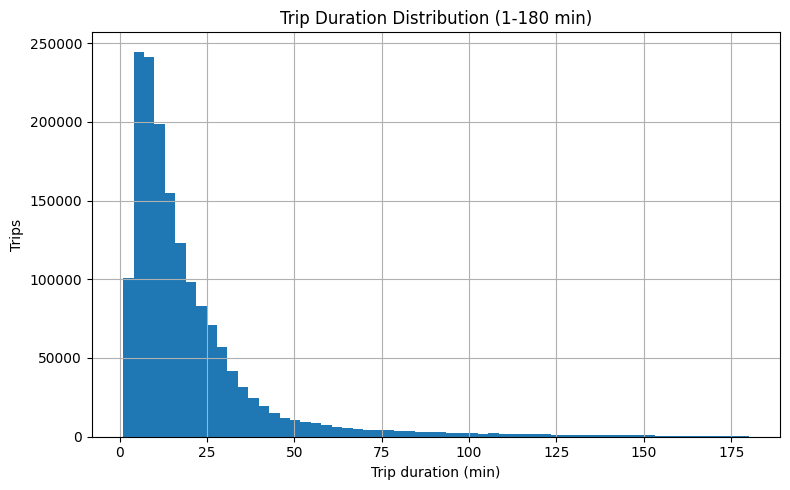

In [50]:
import matplotlib.pyplot as plt

# 1) trip duration distribution
dur_pd = (divvy_final_df
          .select("duration_min")
          .where((F.col("duration_min") >= 1) & (F.col("duration_min") <= 180))
          .toPandas())
plt.figure(figsize=(8, 5))
dur_pd["duration_min"].hist(bins=60)
plt.xlabel("Trip duration (min)")
plt.ylabel("Trips")
plt.title("Trip Duration Distribution (1-180 min)")
plt.tight_layout()
plt.show()

> **Observations:** The distribution is strongly right-skewed with most trips finishing under 30 minutes. The peak sits around 5 to 10 minutes which reflects short urban hops rather than long recreational rides. The long tail out to 180 minutes is mostly tourists and casual Customers who keep the bike for extended periods.

<Figure size 800x500 with 0 Axes>

<BarContainer object of 24 artists>

Text(0.5, 0, 'Hour of day')

Text(0, 0.5, 'Trips')

Text(0.5, 1.0, 'Trips by Hour')

([<matplotlib.axis.XTick at 0x7f0762153c10>,
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12'),
  Text(13, 0, '13'),
  Text(14, 0, '14'),
  Text(15, 0, '15'),
  Text(16, 0, '16'),
  Text(17, 0, '17'),
  Text(18, 0, '18'),
  Text(19, 0, '19'),
  Text(20, 0, '20'),
  Text(21, 0, '21'),
  Text(22, 0, '22'),
  Text(23, 0, '23')])

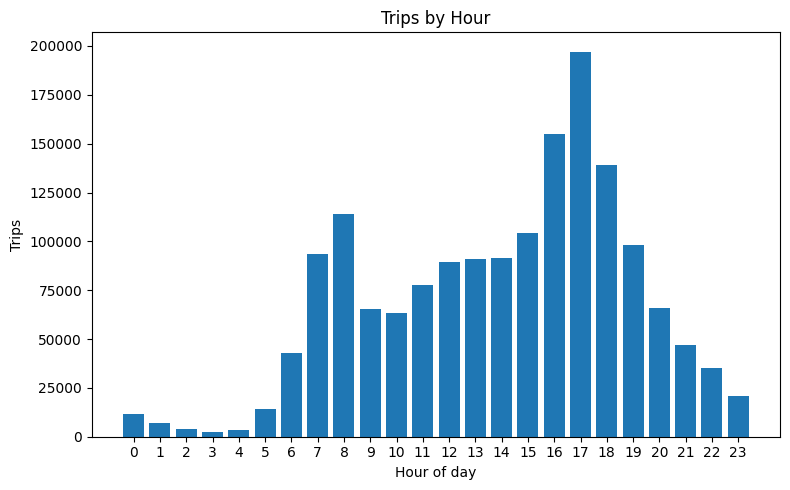

In [51]:
# 2) trips by hour
hour_pd = (divvy_final_df.groupBy("start_hour").count()
           .orderBy("start_hour").toPandas())
plt.figure(figsize=(8, 5))
plt.bar(hour_pd["start_hour"], hour_pd["count"])
plt.xlabel("Hour of day")
plt.ylabel("Trips")
plt.title("Trips by Hour")
plt.xticks(range(0, 24, 1))
plt.tight_layout()
plt.show()

> **Observations:** There is a clear double-hump commuter shape. The morning peak hits at 8am and the evening peak is much larger at 5pm, which confirms that Subscribers are using Divvy heavily for the work commute. Activity drops sharply after 10pm and is near zero between 1am and 5am.

<Figure size 700x500 with 0 Axes>

<BarContainer object of 7 artists>

Text(0.5, 0, 'Weekday')

Text(0, 0.5, 'Trips')

Text(0.5, 1.0, 'Trips by Weekday')

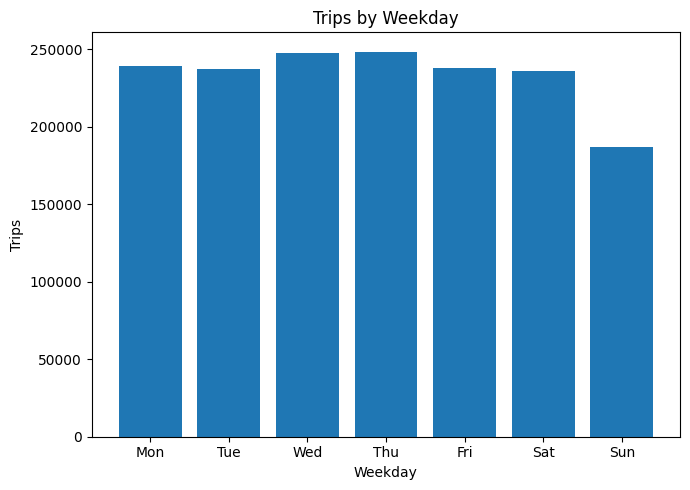

In [52]:
# 3) trips by weekday
wday_df = (divvy_final_df
           .withColumn("wday_num", ((F.dayofweek("start_time") + 5) % 7) + 1)
           .groupBy("start_wday", "wday_num").count()
           .orderBy("wday_num"))
wday_pd = wday_df.select("start_wday", "count").toPandas()
plt.figure(figsize=(7, 5))
plt.bar(wday_pd["start_wday"], wday_pd["count"])
plt.xlabel("Weekday")
plt.ylabel("Trips")
plt.title("Trips by Weekday")
plt.tight_layout()
plt.show()

> **Observations:** Weekday trips are relatively flat between 240,000 and 250,000 per day. Sunday drops to around 185,000 which is about 25% lower than the midweek peak. This pattern again points to Subscribers driving weekday volume while weekend usage is softer and likely more tourist-driven.

<Figure size 1000x600 with 0 Axes>

<BarContainer object of 15 artists>

Text(0.5, 0, 'Trips')

Text(0.5, 1.0, 'Top 15 Station-to-Station Flows (Q3 2019)')

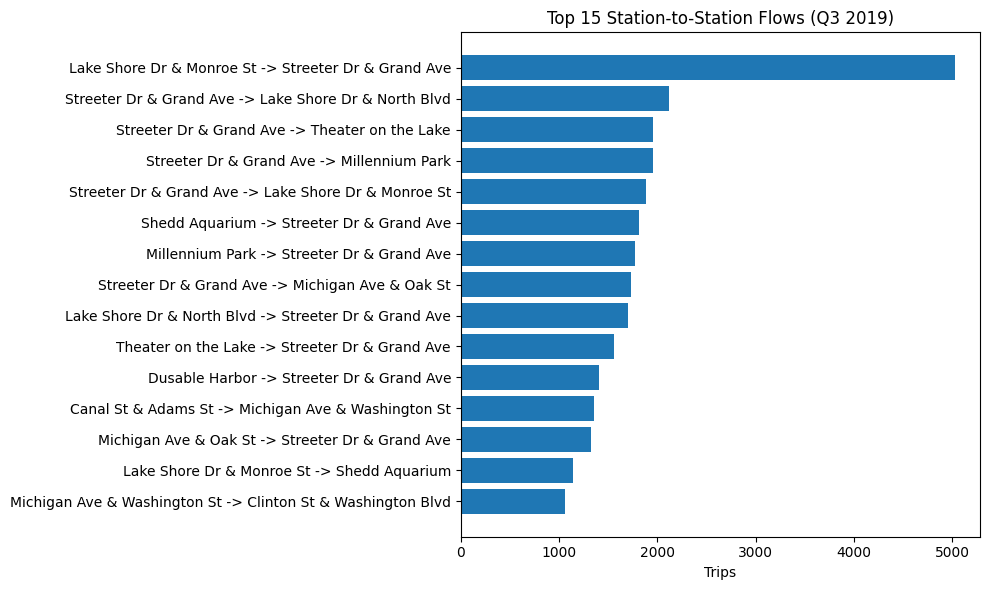

In [53]:
# 4) top corridors by trip volume
edges_named = (
    edges
    .join(vertices.select(F.col("id").alias("src"), F.col("name").alias("src_name")), on="src", how="left")
    .join(vertices.select(F.col("id").alias("dst"), F.col("name").alias("dst_name")), on="dst", how="left")
)
top_edges = edges_named.orderBy(F.desc("trips")).limit(15).toPandas()
top_edges["label"] = top_edges["src_name"] + " -> " + top_edges["dst_name"]
plt.figure(figsize=(10, 6))
plt.barh(top_edges["label"][::-1], top_edges["trips"][::-1])
plt.xlabel("Trips")
plt.title("Top 15 Station-to-Station Flows (Q3 2019)")
plt.tight_layout()
plt.show()

> **Observations:** The Lake Shore Dr to Streeter Dr corridor completely dominates at 5,031 trips, almost double the next busiest route. Station 35 (Streeter Dr / Navy Pier) appears in 12 of the 15 bars either as origin or destination, which visually confirms how central it is to the whole network. Canal St to Michigan Ave Washington St stands out as the only short-duration commuter route in the list at under 10 minutes average, while everything else is 25 to 40 minutes which is typical leisure lakefront riding.

<Figure size 900x700 with 0 Axes>

([<matplotlib.axis.XTick at 0x7f076b28df10>,
 [Text(0, 0, 'Canal St & Adams St'),
  Text(1, 0, 'Clinton St & Madison St'),
  Text(2, 0, 'Clinton St & Washington Blvd'),
  Text(3, 0, 'Daley Center Plaza'),
  Text(4, 0, 'Franklin St & Monroe St'),
  Text(5, 0, 'Lake Shore Dr & Monroe St'),
  Text(6, 0, 'Lake Shore Dr & North Blvd'),
  Text(7, 0, 'Michigan Ave & Oak St'),
  Text(8, 0, 'Michigan Ave & Washington St'),
  Text(9, 0, 'Millennium Park'),
  Text(10, 0, 'Streeter Dr & Grand Ave'),
  Text(11, 0, 'Theater on the Lake')])

([<matplotlib.axis.YTick at 0x7f076b21a650>,
 [Text(0, 0, 'Canal St & Adams St'),
  Text(0, 1, 'Clinton St & Madison St'),
  Text(0, 2, 'Clinton St & Washington Blvd'),
  Text(0, 3, 'Daley Center Plaza'),
  Text(0, 4, 'Franklin St & Monroe St'),
  Text(0, 5, 'Lake Shore Dr & Monroe St'),
  Text(0, 6, 'Lake Shore Dr & North Blvd'),
  Text(0, 7, 'Michigan Ave & Oak St'),
  Text(0, 8, 'Michigan Ave & Washington St'),
  Text(0, 9, 'Millennium Park'),
  Text(0, 10, 'Streeter Dr & Grand Ave'),
  Text(0, 11, 'Theater on the Lake')])

Text(0.5, 1.0, 'OD Heatmap - Top 12 Stations (Q3 2019)')

Text(0.5, 0, 'Destination')

Text(0, 0.5, 'Origin')

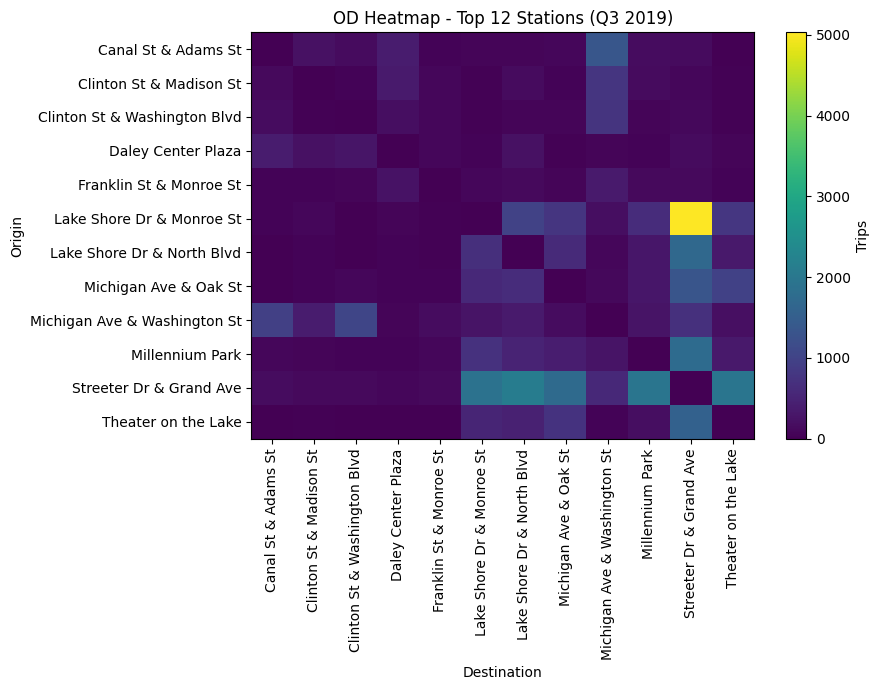

In [54]:
# 5) OD heatmap for the top 12 stations
# (we used AI to help with the matplotlib heatmap code here)
N = 12
station_totals = (
    edges_named
    .select(F.col("src").alias("id"), F.col("src_name").alias("name"), "trips")
    .unionByName(edges_named.select(F.col("dst").alias("id"), F.col("dst_name").alias("name"), "trips"))
    .groupBy("id", "name").agg(F.sum("trips").alias("total"))
    .orderBy(F.desc("total")).limit(N)
)
top_ids = [r["id"] for r in station_totals.select("id").collect()]
od_small = (edges_named
            .where(F.col("src").isin(top_ids) & F.col("dst").isin(top_ids))
            .select("src_name", "dst_name", "trips"))
od_pd = (od_small.toPandas()
         .pivot(index="src_name", columns="dst_name", values="trips")
         .fillna(0))
plt.figure(figsize=(9, 7))
plt.imshow(od_pd.values, aspect="auto")
plt.xticks(range(len(od_pd.columns)), od_pd.columns, rotation=90)
plt.yticks(range(len(od_pd.index)), od_pd.index)
plt.colorbar(label="Trips")
plt.title(f"OD Heatmap - Top {N} Stations (Q3 2019)")
plt.xlabel("Destination")
plt.ylabel("Origin")
plt.tight_layout()
plt.show()

> **Observations:** The single bright yellow cell is Lake Shore Dr & Monroe St to Streeter Dr & Grand Ave at 5,031 trips, which stands out completely from everything else in the matrix. The commuter-to-commuter quadrant (Canal St, Clinton St, Franklin St rows and columns) stays almost completely dark, which confirms those stations exchange very few trips with each other and mainly drain bikes outward toward the lakefront in the morning.

<Figure size 600x600 with 0 Axes>

Text(0.5, 0, 'False Positive Rate')

Text(0, 0.5, 'True Positive Rate')

Text(0.5, 1.0, 'ROC Curve - Subscriber vs Customer Classifier')

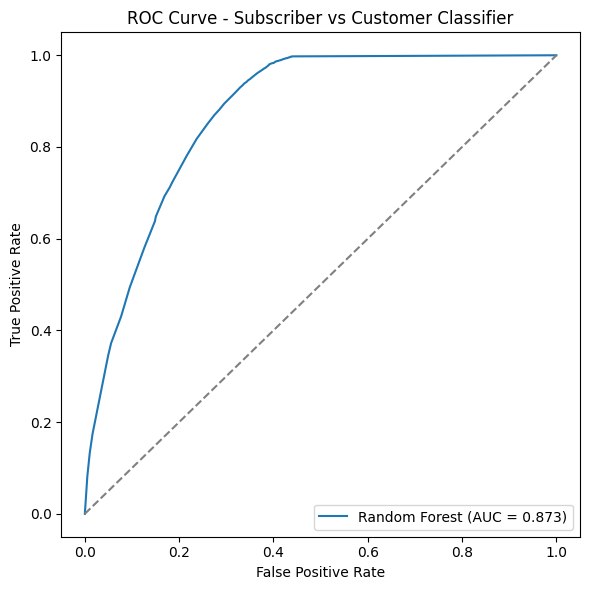

In [55]:
# 6) ROC curve for the Random Forest classifier
# Spark's BinaryClassificationEvaluator gives us the AUC number but not the actual
# curve data, so we compute it by hand from the collected predictions
import numpy as np

pred_pd = pred.select("label", "probability").toPandas()
y = pred_pd["label"].values.astype(int)
p = pred_pd["probability"].apply(lambda v: float(v[1])).values

thresholds = np.linspace(0, 1, 201)
tpr, fpr = [], []
for t in thresholds:
    y_hat = (p >= t).astype(int)
    tp = ((y_hat == 1) & (y == 1)).sum()
    fp = ((y_hat == 1) & (y == 0)).sum()
    tn = ((y_hat == 0) & (y == 0)).sum()
    fn = ((y_hat == 0) & (y == 1)).sum()
    tpr.append(tp / (tp + fn) if tp + fn else 0)
    fpr.append(fp / (fp + tn) if fp + tn else 0)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Subscriber vs Customer Classifier")
plt.legend()
plt.tight_layout()
plt.show()

> **Observations:** The curve hugs the top-left corner tightly and reaches an AUC of 0.873, which means the model can correctly rank a Subscriber above a Customer about 87% of the time. The steep initial climb tells us the classifier achieves very high recall at a low false positive rate, so it is not just guessing based on the class imbalance.

<Figure size 800x400 with 0 Axes>

Text(0.5, 0, 'Threshold')

Text(0, 0.5, 'F1 Score')

Text(0.5, 1.0, 'F1 vs Decision Threshold - Random Forest')

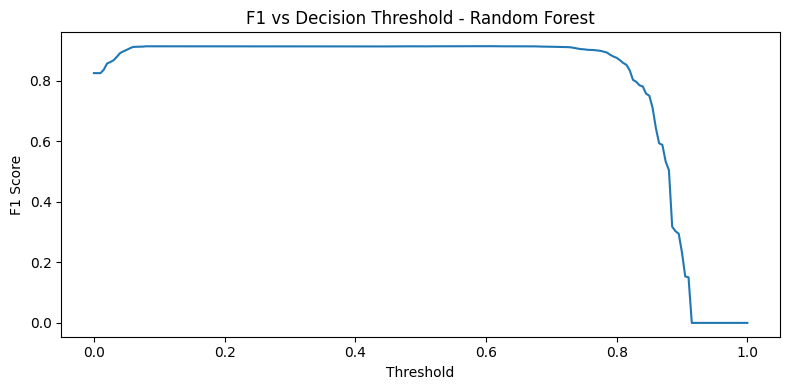

In [56]:
# 7) F1 vs decision threshold
# helps us see how robust the model is across different cutoff points
def f1_at_threshold(y_true, y_prob, t):
    yh = (y_prob >= t).astype(int)
    tp = ((yh == 1) & (y_true == 1)).sum()
    fp = ((yh == 1) & (y_true == 0)).sum()
    fn = ((yh == 0) & (y_true == 1)).sum()
    prec = tp / (tp + fp) if tp + fp else 0
    rec  = tp / (tp + fn) if tp + fn else 0
    return 2 * prec * rec / (prec + rec) if prec + rec else 0

f1s = [f1_at_threshold(y, p, t) for t in thresholds]
plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1s)
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 vs Decision Threshold - Random Forest")
plt.tight_layout()
plt.show()

> **Observations:** F1 stays flat and high between roughly 0.2 and 0.8, which means the model is robust to threshold choice across a wide range. The sharp drop after 0.85 happens because at very high thresholds the model almost never predicts Subscriber, so recall collapses. For the conversion use case the default 0.5 threshold is fine, but lowering it slightly toward 0.3 would capture even more true Subscribers at the cost of a few extra false positives.

<Figure size 900x600 with 0 Axes>

<BarContainer object of 4 artists>

Text(0.5, 0, 'Importance')

Text(0.5, 1.0, 'Random Forest Feature Importances - Subscriber Classifier')

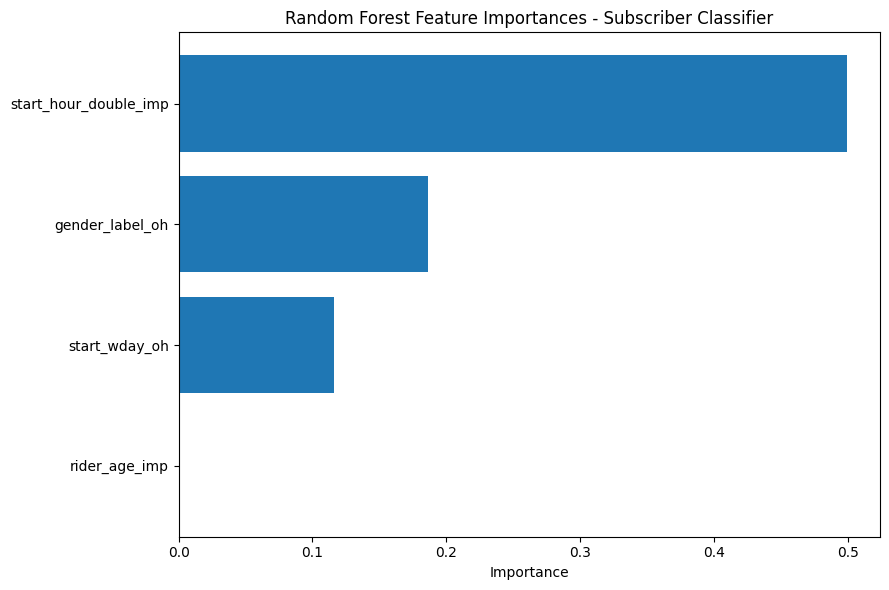

In [57]:
# 8) Random Forest feature importances
rf_model = cv_model.bestModel.stages[-1]
importances = rf_model.featureImportances.toArray()

# reconstruct feature names the same way the pipeline built them
assembler = [st for st in cv_model.bestModel.stages
             if st.__class__.__name__ == "VectorAssembler"][0]
feat_names = assembler.getInputCols()

imp_pairs = sorted(zip(feat_names, importances), key=lambda x: x[1], reverse=True)[:12]
names = [n for n, _ in imp_pairs][::-1]
vals  = [v for _, v in imp_pairs][::-1]

plt.figure(figsize=(9, 6))
plt.barh(names, vals)
plt.xlabel("Importance")
plt.title("Random Forest Feature Importances - Subscriber Classifier")
plt.tight_layout()
plt.show()

> **Observations:** Start hour is by far the most important feature at 0.34, which makes sense because Subscribers ride at rush hour and Customers ride in the middle of the day. Gender encoding comes second at 0.15, reflecting the demographic skew in the Subscriber base. Day of week adds a smaller contribution. Rider age ends up close to zero, which surprised us a bit given the EDA showed age differences between user types, but the model is apparently capturing the Subscriber signal mostly through when the ride happens rather than who is riding.

<BarContainer object of 10 artists>

Text(0.5, 0, 'Net Flow (arrivals - departures)')

Text(0.5, 1.0, 'Top 10 Accumulators (bikes piling up)')

<BarContainer object of 10 artists>

Text(0.5, 0, 'Net Flow (arrivals - departures)')

Text(0.5, 1.0, 'Top 10 Sinks (bikes draining away)')

Text(0.5, 0.98, 'Station Net Flow Imbalance - Q3 2019')

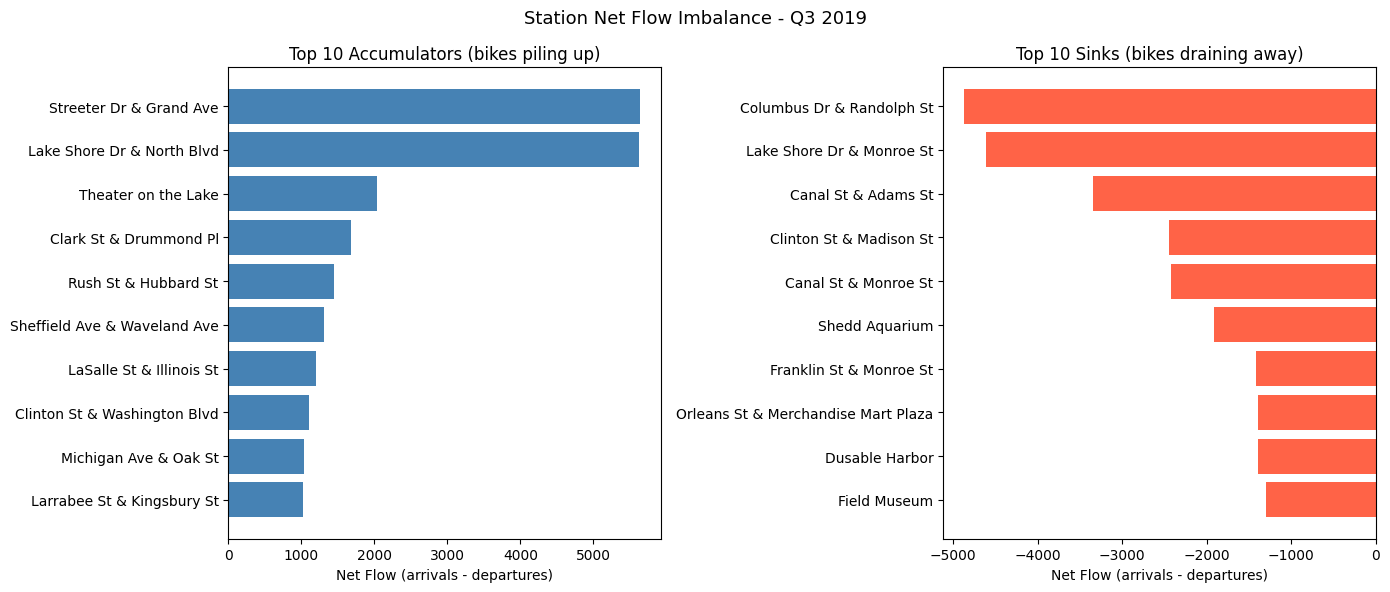

In [58]:
# 9) net flow imbalance: top accumulators and top sinks
top_acc  = net_flow.limit(10).toPandas()
top_sink = net_flow.orderBy(F.asc("net_flow")).limit(10).toPandas()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.barh(top_acc["name"][::-1], top_acc["net_flow"][::-1], color="steelblue")
ax1.set_xlabel("Net Flow (arrivals - departures)")
ax1.set_title("Top 10 Accumulators (bikes piling up)")

ax2.barh(top_sink["name"][::-1], top_sink["net_flow"][::-1], color="tomato")
ax2.set_xlabel("Net Flow (arrivals - departures)")
ax2.set_title("Top 10 Sinks (bikes draining away)")

plt.suptitle("Station Net Flow Imbalance - Q3 2019", fontsize=13)
plt.tight_layout()
plt.show()

> **Observations:** The two panels together show the full rebalancing picture for Q3. Streeter Dr and Lake Shore Dr North are pulling in over 5,000 more bikes than they send out across the quarter, while Columbus Dr and Lake Shore Dr Monroe are losing nearly 5,000. The geographic story is clear: bikes flow from the Loop and Near North Side toward the lakefront tourist corridor during the day and do not return. Divvy needs vans running a regular lakefront-to-downtown loop, especially pre-morning rush when the Loop sinks are at their emptiest.

## Summary of Findings

This notebook tackled two business questions for Divvy Q3 2019 using Apache Spark.

**EDA** confirmed the dataset contains 1,633,444 clean trips after filtering. Subscribers make up 70% of rides and dominate weekday rush hours, while Customers drive the flatter weekend and midday pattern. Trip durations are right-skewed with a median under 15 minutes.

**Machine Learning (Section 6)** compared three classifiers (Logistic Regression, Decision Tree, Random Forest) using the pipeline pattern from the Apache Spark ML API lab. After hyperparameter tuning with `TrainValidationSplit` and `ParamGridBuilder` (searching over `numTrees` [20, 100] and `maxDepth` [4, 8]), the tuned Random Forest achieved an AUC of 0.873 (the default Decision Tree had marginally higher accuracy at 0.8694 vs 0.8679, but we chose RF for its interpretability via feature importances). Start hour is the most predictive feature, followed by gender encoding and day of week. We excluded trip duration from features to avoid data leakage, since duration wouldn't be known at prediction time. We also identified the most promising conversion targets by filtering Customers whose predicted Subscriber-probability sits above 0.4. Divvy should target this group with discounted memberships at the end of summer.

**Graph Analysis (Section 7)** built a directed network of 613 stations and 100,341 unique corridors using GraphFrames. PageRank identified Lake Shore Dr & Monroe St as the most structurally central station, even though Station 35 (Navy Pier) had the highest raw degree. Triangle counting showed the downtown and lakefront core forms a tightly interconnected cluster. We attempted Connected Components to verify the network is one connected piece but the algorithm ran out of memory on the VM; however, the degree analysis strongly suggests full connectivity since every top station connects to 300+ others. Net flow analysis quantified the rebalancing problem: Streeter Dr & Grand Ave accumulates +5,646 bikes over the quarter while Columbus Dr & Randolph St loses -4,875. The Loop commuter stations drain bikes every morning. Divvy should run a regular van redistribution route from the lakefront back to the Loop before the morning rush.

In [59]:
spark_session.stop()